数据流水线与性能
分析对象：把 01-04 的手工步骤封装成可重复运行的流水线，并做性能与幂等
    1 清洗封装 clean()
    2 维度封装 build_stands() / build_grid()
    3 端到端 pipeline()
    4 幂等性：连跑两遍，结果一致（assert 对账，不靠眼睛）
    5 性能：各阶段耗时；CSV vs pickle 读取对比
    6 可选引擎（polars / duckdb / pyarrow）：装了才测，没装如实标注

In [1]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import taxi_common as tc

SCRIPT = "数据流水线与性能"
tc.AUTHOR = "薛宏博 2428324276"
SOURCE = tc.source_line(SCRIPT)
tc.apply_theme()

LNG_OK, LAT_OK = (-9.0, -8.0), (40.8, 41.6)
LAT0 = 41.15
KM_LAT = 1 / 111.0
KM_LNG = 1 / (111.32 * np.cos(np.radians(LAT0)))

In [2]:
# 清洗封装
def clean(raw: pd.DataFrame) -> pd.DataFrame:
    """D2 清洗规则的函数化：空轨迹 -> 完全重复 -> 首点越界。"""
    d = raw[raw["n_pts"] > 0]
    d = d[~d.duplicated(
        subset=["TRIP_ID", "TAXI_ID", "TIMESTAMP", "POLYLINE"], keep="first")]
    d = d[d["lng0"].between(*LNG_OK) & d["lat0"].between(*LAT_OK)]
    return d.reset_index(drop=True)

In [3]:
# 维度封装
def build_grid(dwd: pd.DataFrame) -> pd.DataFrame:
    lng_min, lat_min = dwd["lng0"].min(), dwd["lat0"].min()
    dwd = dwd.copy()
    dwd["gx"] = np.floor((dwd["lng0"] - lng_min) / KM_LNG).astype(int)
    dwd["gy"] = np.floor((dwd["lat0"] - lat_min) / KM_LAT).astype(int)
    return dwd

def build_stands(dwd: pd.DataFrame) -> pd.DataFrame:
    h = dwd[dwd["ORIGIN_STAND"].notna()]
    st = (h.assign(STAND=h["ORIGIN_STAND"].astype(int)).groupby("STAND")
          .agg(lng=("lng0","median"), lat=("lat0","median"),
               发车趟次=("TRIP_ID","size")).reset_index())
    return st

In [4]:
# 端到端流水线
def pipeline(use_cache: bool = True):
    """返回各层产物 + 各阶段耗时。"""
    timings = {}
    t0 = time.perf_counter()
    raw = tc.load_raw(use_cache=use_cache)
    timings["接入加载"] = time.perf_counter() - t0

    t0 = time.perf_counter(); dwd = clean(raw)
    timings["清洗"] = time.perf_counter() - t0

    t0 = time.perf_counter(); dwd = build_grid(dwd)
    timings["网格划分"] = time.perf_counter() - t0

    t0 = time.perf_counter(); stands = build_stands(dwd)
    timings["站台维度"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    hourly = dwd.groupby("hour").agg(趟次=("TRIP_ID","size"),
                                     车辆=("TAXI_ID","nunique"))
    timings["聚合"] = time.perf_counter() - t0
    return {"raw": raw, "dwd": dwd, "stands": stands,
            "hourly": hourly, "timings": timings}

In [5]:
# 跑流水线 + 幂等
print("第一次运行（含缓存）\n")
r1 = pipeline(use_cache=True)
for k, v in r1["timings"].items():
    print(f"{k:10s} {v*1000:8.1f} ms")

print("\n第二次运行（幂等性检查）")
r2 = pipeline(use_cache=True)
# 对账：关键层结果必须一致
assert len(r1["dwd"]) == len(r2["dwd"]), "DWD 行数不一致"
assert len(r1["stands"]) == len(r2["stands"]), "站台数不一致"
pd.testing.assert_frame_equal(
    r1["hourly"].reset_index(), r2["hourly"].reset_index())
print("幂等断言通过：两遍 DWD / 站台 / 小时聚合完全一致")

第一次运行（含缓存）

接入加载         4300.9 ms
清洗            479.9 ms
网格划分           48.6 ms
站台维度           63.7 ms
聚合             16.2 ms

第二次运行（幂等性检查）
幂等断言通过：两遍 DWD / 站台 / 小时聚合完全一致


In [6]:
# 读取性能
print("读取性能（各 3 次取最小，秒）\n")
def bench_csv():
    t = time.perf_counter()
    df = pd.read_csv(tc.DATA_PATH)
    return time.perf_counter() - t
def bench_csv_full():
    # 含 POLYLINE 解析与时间换算（load_raw 的完整成本）
    t = time.perf_counter()
    tc.load_raw(use_cache=False)
    return time.perf_counter() - t
def bench_pickle():
    t = time.perf_counter()
    pd.read_pickle(tc.CACHE_DIR / "raw_base.pkl")
    return time.perf_counter() - t

csv_t = min(bench_csv() for _ in range(2))
full_t = bench_csv_full()
pk_t = min(bench_pickle() for _ in range(3))
print(f"纯 read_csv           {csv_t:6.2f} s")
print(f"CSV+JSON解析+时间换算 {full_t:6.2f} s")
print(f"pickle 缓存读取       {pk_t:6.2f} s")
print(f"pickle 相比完整解析提速 {full_t/pk_t:.0f} 倍")

# 可选引擎
opt = {}
for m in ["polars", "duckdb", "pyarrow"]:
    try:
        __import__(m); opt[m] = True
    except Exception:
        opt[m] = False
print("\n可选引擎：", {k: ("已装" if v else "未装") for k, v in opt.items()})

读取性能（各 3 次取最小，秒）

纯 read_csv             1.62 s
CSV+JSON解析+时间换算  22.36 s
pickle 缓存读取         2.76 s
pickle 相比完整解析提速 8 倍

可选引擎： {'polars': '未装', 'duckdb': '未装', 'pyarrow': '已装'}


In [7]:
# 各阶段数据
timings = r1["timings"]
stage = pd.Series(timings).sort_values()
total = sum(timings.values())

findfont: Failed to find font weight normal for Noto Sans SC, now using 100.
findfont: Failed to find font weight normal for Noto Sans SC, now using 100.
findfont: Failed to find font weight bold for Noto Sans SC, now using 100.
findfont: Failed to find font weight normal for Noto Sans SC, now using 100.
findfont: Failed to find font weight normal for Noto Sans SC, now using 100.


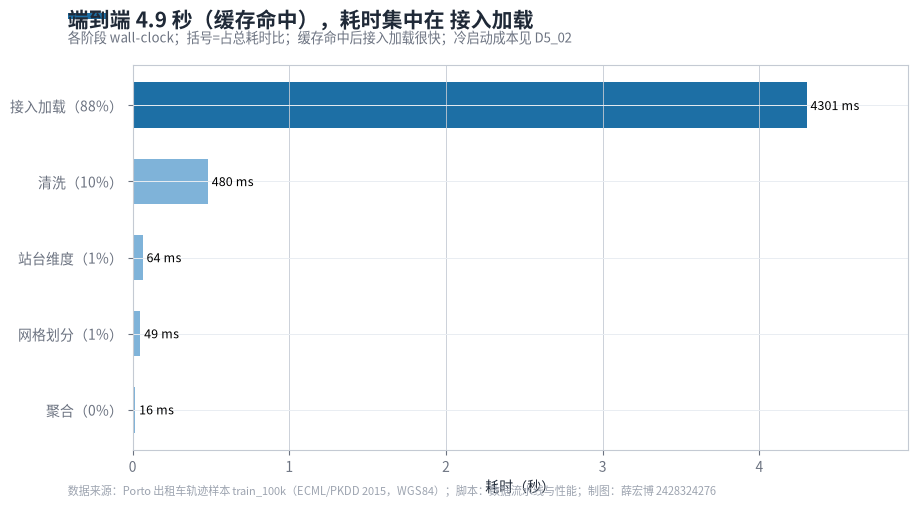

In [8]:
# 各阶段耗时
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
colors = [tc.MAIN if k == stage.idxmax() else tc.MAIN_MID for k in stage.index]
ax.barh(range(len(stage)), stage.values, color=colors, height=.6)
ax.set_yticks(range(len(stage)))
ax.set_yticklabels([f"{k}（{v/total:.0%}）" for k, v in stage.items()])
for i, v in enumerate(stage.values):
    ax.text(v + total*.005, i, f"{v*1000:.0f} ms", va="center", fontsize=9)
ax.set_xlim(0, stage.max()*1.15)
ax.set_xlabel("耗时（秒）")
ax.grid(axis="x", color=tc.GRAY, lw=.6)
tc.finish(
    fig,
    f"端到端 {total:.1f} 秒（缓存命中），耗时集中在 {stage.idxmax()}",
    "各阶段 wall-clock；括号=占总耗时比；缓存命中后接入加载很快；冷启动成本见 D5_02",
    SOURCE, "D5_01_各阶段耗时.png")
plt.show()

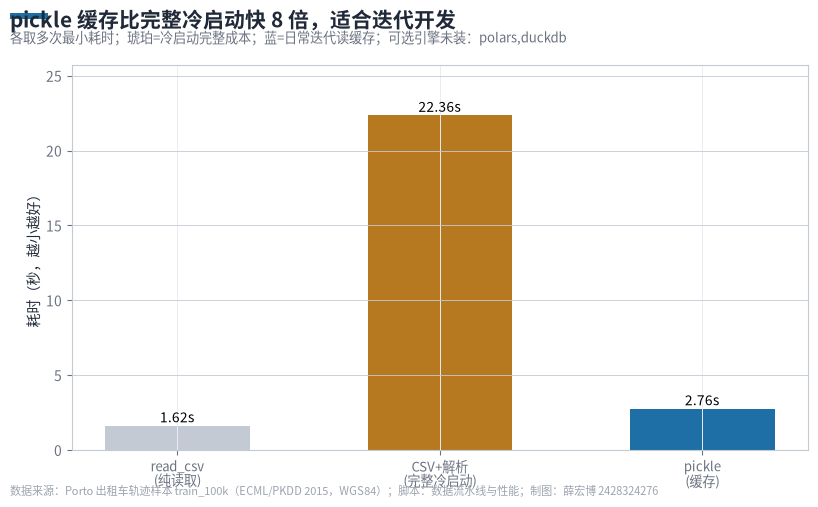

完成：图片已保存至 C:\Users\fish\Desktop\data-analysis-project-2026-main\image


In [9]:
# 读取性能对比
fig, ax = plt.subplots(figsize=(9.5, 5), dpi=100)
names = ["read_csv\n(纯读取)", "CSV+解析\n(完整冷启动)", "pickle\n(缓存)"]
vals = [csv_t, full_t, pk_t]
colors = [tc.GRAY, tc.AMBER, tc.MAIN]
bars = ax.bar(range(3), vals, color=colors, width=.55)
ax.set_xticks(range(3)); ax.set_xticklabels(names, fontsize=9.5)
for i, v in enumerate(vals):
    ax.text(i, v + max(vals)*.01, f"{v:.2f}s", ha="center", fontsize=10)
ax.set_ylabel("耗时（秒，越小越好）")
ax.set_ylim(0, max(vals)*1.15)
ax.grid(axis="y", color=tc.GRAY, lw=.6)
note = "；可选引擎未装：" + ",".join(k for k,v in opt.items() if not v)
tc.finish(
    fig,
    f"pickle 缓存比完整冷启动快 {full_t/pk_t:.0f} 倍，适合迭代开发",
    "各取多次最小耗时；琥珀=冷启动完整成本；蓝=日常迭代读缓存" + note,
    SOURCE, "D5_02_读取性能.png")
plt.show()
print("完成：图片已保存至", tc.IMAGE_DIR)